# Experiment 6 — Linear Regression and Diagnostics (Iris Dataset)

**Covers:** Multiple linear regression (OLS), correlation heatmap, coefficient table, R², adjusted R², MSE, RMSE, MAE, actual vs predicted, VIF, residual plots, Cook's distance and CSV export.

**Dataset:** **Iris** – `Iris.csv` from Kaggle ([uciml/iris](https://www.kaggle.com/datasets/uciml/iris)), 150 flowers, columns `Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species`.

**Data file:** keep `Iris.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\Iris.csv")`).

**Remember:** OLS → Metrics → VIF → Residuals → Cook's Distance → Summary.

Target: `PetalWidthCm`, predicted from the other three measurements.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("Iris.csv")

## 1. Select data

       PetalWidthCm  PetalLengthCm  SepalLengthCm  SepalWidthCm
count    150.000000     150.000000     150.000000    150.000000
mean       1.198667       3.758667       5.843333      3.054000
std        0.763161       1.764420       0.828066      0.433594
min        0.100000       1.000000       4.300000      2.000000
25%        0.300000       1.600000       5.100000      2.800000
50%        1.300000       4.350000       5.800000      3.000000
75%        1.800000       5.100000       6.400000      3.300000
max        2.500000       6.900000       7.900000      4.400000


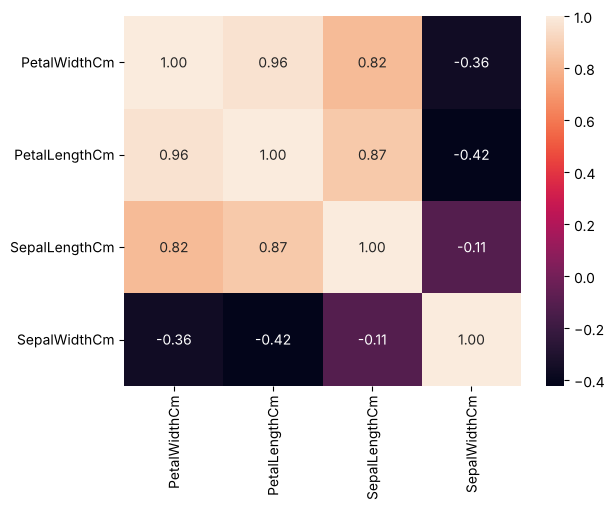

In [2]:
cols = ["PetalLengthCm", "SepalLengthCm", "SepalWidthCm"]
data = df[["PetalWidthCm"] + cols].dropna()
print(data.describe())

sns.heatmap(data.corr(), annot=True, fmt=".2f")
plt.show()

X = data[cols]
y = data["PetalWidthCm"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 2. Linear regression (OLS)

In [3]:
model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model.summary())

coef = pd.DataFrame({
    "Coefficient": model.params,
    "Std Error": model.bse,
    "t": model.tvalues,
    "p": model.pvalues
})
print(coef)

                            OLS Regression Results                            
Dep. Variable:           PetalWidthCm   R-squared:                       0.941
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     613.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           5.97e-71
Time:                        11:08:28   Log-Likelihood:                 33.675
No. Observations:                 120   AIC:                            -59.35
Df Residuals:                     116   BIC:                            -48.20
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.1791      0.188     -0.954

## 3. Predictions and evaluation

Train R2: 0.9406642953714707
Adjusted R2: 0.9391297512862501
Test R2: 0.9269445514568614
MSE: 0.04643810173004905 RMSE: 0.21549501555731876 MAE: 0.15902189408975362


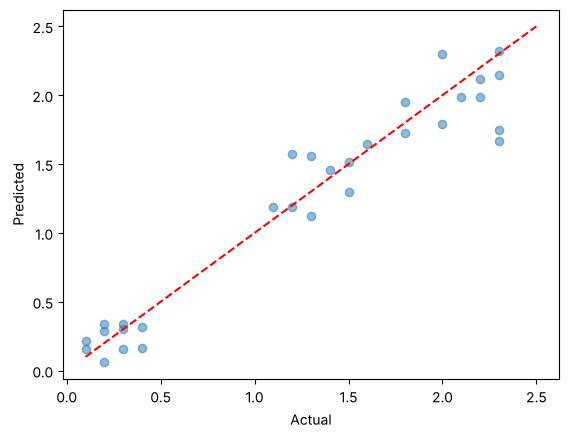

In [4]:
pred = model.predict(sm.add_constant(X_test))

mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

print("Train R2:", model.rsquared)
print("Adjusted R2:", model.rsquared_adj)
print("Test R2:", r2)
print("MSE:", mse, "RMSE:", rmse, "MAE:", mae)

plt.scatter(y_test, pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

## 4. VIF (multicollinearity)
VIF > 5 → moderate, VIF > 10 → high multicollinearity.

         Feature       VIF
0  PetalLengthCm  7.099116
1  SepalLengthCm  5.887816
2   SepalWidthCm  1.839293


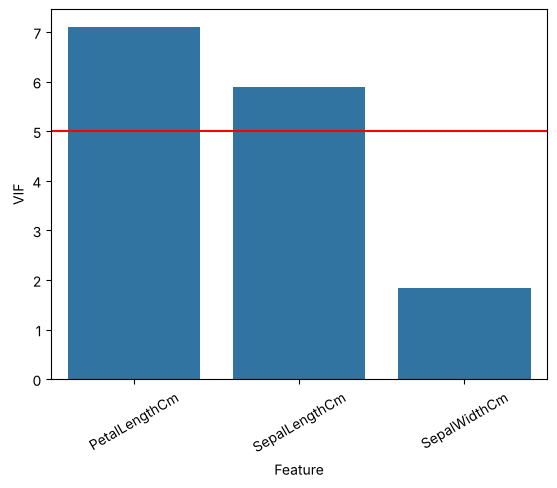

In [5]:
vif = pd.DataFrame({
    "Feature": cols,
    "VIF": [variance_inflation_factor(
        sm.add_constant(X_train).values, i + 1
    ) for i in range(len(cols))]
})
print(vif)

sns.barplot(data=vif, x="Feature", y="VIF")
plt.axhline(5, color="red")
plt.xticks(rotation=30)
plt.show()

## 5. Residual analysis

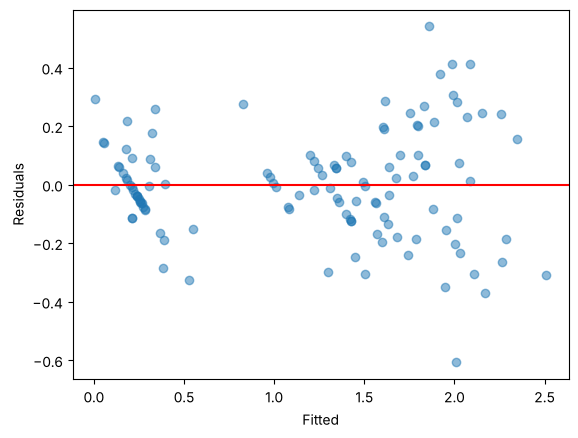

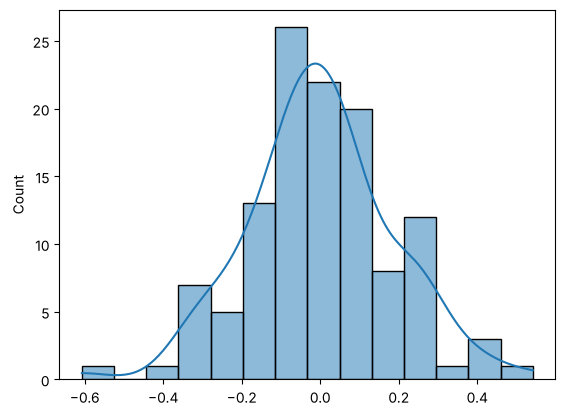

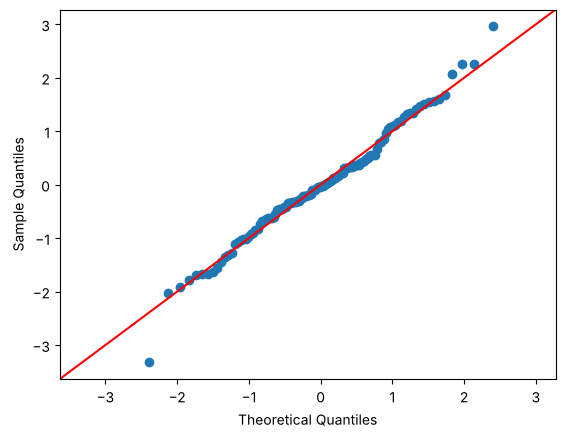

In [6]:
res = model.resid

plt.scatter(model.fittedvalues, res, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.show()

sns.histplot(res, kde=True)
plt.show()

sm.qqplot(res, line="45", fit=True)
plt.show()

## 6. Cook's distance (influential points)
Rule of thumb: Cook's D > 4/n is influential.

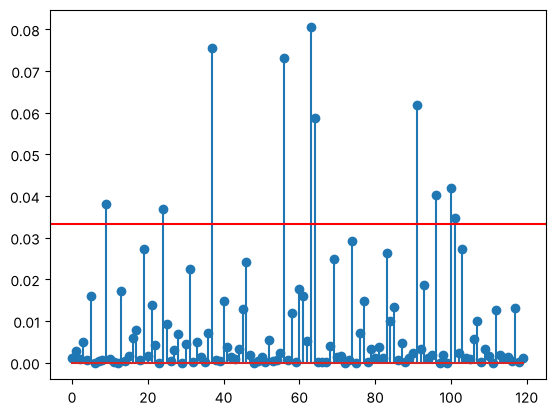

     Actual    Fitted  Residual  Std Residual   Cooks D
134     1.4  2.007145 -0.607145     -3.313812  0.080657
117     2.2  2.508483 -0.308483     -1.740274  0.075493
114     2.4  1.858745  0.541255      2.959976  0.073204
41      0.3  0.007016  0.292984      1.646591  0.061961
135     2.3  1.992091  0.307909      1.720944  0.058809
144     2.5  2.088167  0.411833      2.251848  0.041952
107     1.8  2.170284 -0.370284     -2.030396  0.040149
32      0.1  0.385179 -0.285179     -1.580290  0.038126
122     2.0  2.265522 -0.265522     -1.475892  0.036819
129     1.6  1.950014 -0.350014     -1.918095  0.034678


In [7]:
influence = OLSInfluence(model)
cooks = influence.cooks_distance[0]
limit = 4 / len(X_train)

plt.stem(range(len(cooks)), cooks)
plt.axhline(limit, color="red")
plt.show()

diagnostics = pd.DataFrame({
    "Actual": y_train,
    "Fitted": model.fittedvalues,
    "Residual": res,
    "Std Residual": influence.resid_studentized_internal,
    "Cooks D": cooks
})

print(diagnostics[diagnostics["Cooks D"] > limit].sort_values("Cooks D", ascending=False).head(10))

## 7. Summary and save

In [8]:
summary = pd.DataFrame({
    "Metric": ["Train R2", "Adjusted R2", "Test R2",
               "MSE", "RMSE", "MAE", "Max VIF", "Influential"],
    "Value": [model.rsquared, model.rsquared_adj, r2,
              mse, rmse, mae, vif["VIF"].max(), (cooks > limit).sum()]
})
print(summary)

coef.to_csv("coefficients.csv")
vif.to_csv("vif.csv", index=False)
diagnostics.to_csv("diagnostics.csv")
summary.to_csv("regression.csv", index=False)
print("Saved coefficients.csv, vif.csv, diagnostics.csv, regression.csv")

        Metric      Value
0     Train R2   0.940664
1  Adjusted R2   0.939130
2      Test R2   0.926945
3          MSE   0.046438
4         RMSE   0.215495
5          MAE   0.159022
6      Max VIF   7.099116
7  Influential  10.000000
Saved coefficients.csv, vif.csv, diagnostics.csv, regression.csv


## Result / Conclusion
- Model: `PetalWidthCm` ~ `PetalLengthCm` + `SepalLengthCm` + `SepalWidthCm`. All three predictors are significant (p < 0.001).
- Train R² = 0.941, adjusted R² = 0.939, **test R² = 0.927**, RMSE = 0.215 cm.
- VIF: `PetalLengthCm` 7.1 and `SepalLengthCm` 5.9 show moderate multicollinearity (> 5); `SepalWidthCm` is fine (1.8).
- Residuals are centred on 0 and close to the Q-Q line. 10 points exceed Cook's 4/n limit, but the largest D is only 0.08, so no point dominates the model.